# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import galsim
import ultranest as un
from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology

import astropy.units as u
from astropy.cosmology import FlatLambdaCDM, Planck18 
from astropy import constants
from astropy import table

from scipy import integrate
import xlensing
import cluster_toolkit
import glob
import tqdm

Lookup table loaded!


In [2]:
datadir = "/home/andre/data/TNG_SIMULATED_SHEAR_CATALOGS"

## Defining Units and scalings between codes

In [3]:
Mhalo = 1e14
conc = 5.
zhalo = .3
zsource = 1.0
OmegaM = 0.3
OmegaL = 0.7
astropy_cosmo = Planck18#FlatLambdaCDM(H0=.7,Om0=OmegaM)
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [4]:
radii_mpc = np.linspace(0.01,10,1000)
ang_radii = np.degrees(radii_mpc/astropy_cosmo.angular_diameter_distance(.3).value)*3600
positions = [galsim.PositionD(0.,sep) for sep in ang_radii]

In [5]:
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

In [6]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmo (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, astropy_cosmo)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2e}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, astropy_cosmo)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2e}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2.02e+09 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2.48e+09 solMass / kpc2


In [7]:
def deltasigma_nfw_colossus(colossus_profile,z_source,r):
    z_lens = zhalo
    Sigma_bar = 2*(integrate.quad(lambda r : colossus_profile.surfaceDensity(r)*r,1e-8,r,epsabs=0.,limit=150))[0]/r**2
    Sigma = colossus_profile.surfaceDensity(r)
    deltasigma = Sigma_bar - Sigma
    return deltasigma/1e6

In [8]:
scrit=critical_surface_density(z_l=0.3, z_s=1.0, cosmo=astropy_cosmo).value/1e6

In [9]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

In [10]:
from cluster_toolkit import deltasigma

Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(
    R=radii_mpc,
    Rs=radii_mpc,
    Sigma=Sigma_nfw,
    mass=Mhalo,
    concentration=conc,
    Omega_m=OmegaM,
    delta=200,
)

In [11]:
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_xlensing = xlensing_res['NFW Signal']

In [12]:
delta_sigma_galsim = shears_galsim[:,0]*scrit

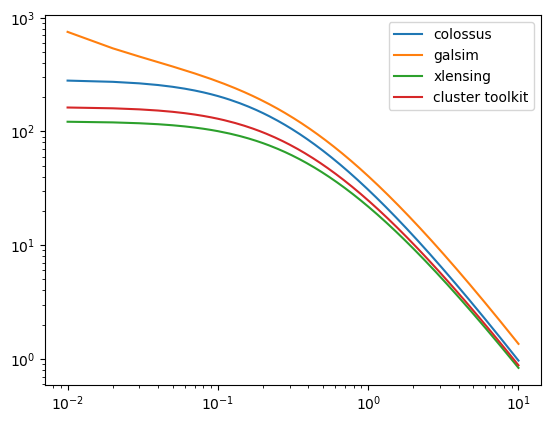

In [13]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
plt.yscale('log')
plt.legend()

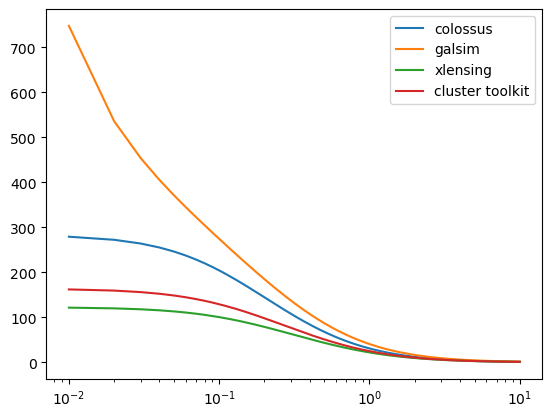

In [14]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
#plt.yscale('log')
plt.legend()

In [15]:
radii_mpc = np.logspace(-2,1,10)

In [16]:
%%timeit
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

33.3 ms ± 889 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

77.6 ms ± 1.28 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
%%timeit
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)

6.81 ms ± 228 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
%%timeit
Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(R=radii_mpc,Rs=radii_mpc,Sigma=Sigma_nfw,mass=Mhalo,concentration=conc,Omega_m=OmegaM,delta=200,
)

23.7 μs ± 1.19 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Generating a field of galaxies

In [20]:
nbar = 30 

In [21]:
simplecat = xlensing.sims.make_simple_random_cat(nbar, width_rad=4./xlensing.cosmo.DA(0,zhalo), zrange=[0.2,1.0], shape_noise=0.25)
simplecat = table.Table(simplecat.T,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])

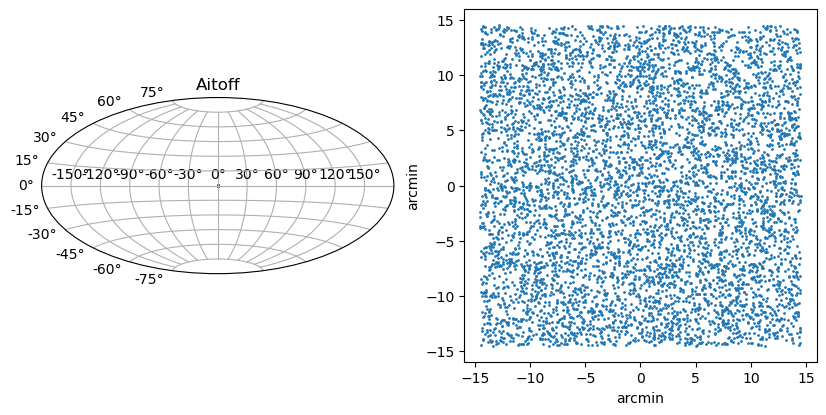

In [22]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
plt.scatter(simplecat['ra'],simplecat['dec'],s=1)
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(simplecat['ra'])*60,np.degrees(simplecat['dec'])*60,s=1)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [23]:
def simcluster(gal_density,total_radius,z_range,cluster,shape_noise,seed=31415):
    cat = xlensing.sims.make_simple_random_cat(
        density=gal_density, 
        width_rad=total_radius/xlensing.cosmo.DA(0,0.3), 
        zrange=z_range, 
        shape_noise=shape_noise,
        seed=seed
    ).T
    cat = xlensing.sims.apply_NFW_shear_region(cluster,cat)
    cat = table.Table(cat,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])
    return cat 

In [24]:
cluster = [0.,0.,.3,1e14,5.] 

In [25]:
n_gal_factor = 10

In [26]:
cluster_test = simcluster(gal_density=30,total_radius=10,z_range=[.3,2.],cluster=cluster,shape_noise=0.25/np.sqrt(n_gal_factor),seed=None)

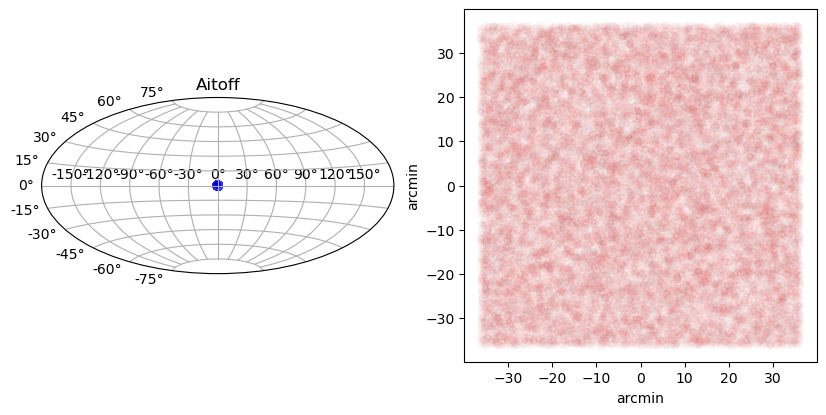

In [27]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
ellip = np.sqrt(cluster_test['e1']**2+ cluster_test['e2']**2)
plt.scatter(cluster_test['ra'],cluster_test['dec'],s=(cluster_test['z']+1)*10,c=ellip,cmap='seismic')
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(cluster_test['ra'])*60,np.degrees(cluster_test['dec'])*60,s=(cluster_test['z']+1)*10,c=np.log10(ellip),cmap='seismic',alpha=.01)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [28]:
galaxy_catalog = {}
galaxy_catalog['RA'] = cluster_test['ra']
galaxy_catalog['DEC'] = cluster_test['dec']
galaxy_catalog['ZPHOT'] = cluster_test['z']
galaxy_catalog['E1'] = cluster_test['e1']
galaxy_catalog['E2'] = cluster_test['e2']
galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
galaxy_catalog = table.Table(galaxy_catalog)

## Fitting

In [29]:
clusters = table.Table([[0],[0],[0.3]],names=['RA','DEC', 'Z'])

In [30]:
sr_RA = np.array(galaxy_catalog['RA'])
sr_DEC= np.array(galaxy_catalog['DEC'])
sr_z  = np.array(galaxy_catalog['ZPHOT'])
sr_E1 = np.array(galaxy_catalog['E1'])
sr_E2 = np.array(galaxy_catalog['E2'])
sr_W = np.array(galaxy_catalog['WEIGHT'])
sr_M = np.array(galaxy_catalog['M'])

clusters['INDEX'] = np.array(range(len(clusters)))

In [31]:
galaxy_catalog

RA,DEC,ZPHOT,E1,E2,WEIGHT,M
float64,float64,float64,float64,float64,float64,float64
0.004702159634898421,0.0013736817490156272,0.3911980955981551,0.06715829204058685,0.13190108418346896,1.0,0.0
0.010149421696165135,0.001676436678148003,1.2768680314815684,-0.05864681009115208,-0.18142619090081702,1.0,0.0
-0.003229697678910056,0.008087664302682332,0.8277269599300925,-0.0010022909267024451,0.014167178162573579,1.0,0.0
-0.006421113827892502,-0.005009668986649776,0.787601662246384,-0.1518742539352342,-0.03686820799292721,1.0,0.0
-0.01006068117603726,-0.00043304442800481784,1.168612196073347,0.09142476260943119,-0.1512606716624505,1.0,0.0
0.0019285458151045362,0.0020021512864467784,0.48217055742830306,0.1494744905662373,0.1186694048695749,1.0,0.0
0.009513133829290612,0.00766960422393324,0.6237469515167255,-0.022789085031259638,-0.031555604114798165,1.0,0.0
0.008476059522416247,-0.007514092788123045,0.34384673320517206,-0.012465941105993528,-0.08092960913594853,1.0,0.0
0.0013709261379466434,0.008855418222170508,1.3808795231705224,0.004784779950590723,-0.16060283489284338,1.0,0.0


In [32]:
cl_RA=np.array(clusters['RA'])
cl_DEC= np.array(clusters['DEC'])
cl_z= np.array(clusters['Z'])
cl = np.array([cl_RA,cl_DEC,cl_z]).T

In [33]:
#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

# you can use whatever, but your machine core count is usually a good choice (although maybe not the best)
pool = Pool(cpu_count()) 

#We get a partial function with a constant galaxy catalogue to iterate with clusters.
survey_lensing = partial(
    xlensing.data.lensfit_cluster_lensing,
    sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
    radius=10.
)

In [34]:
clz = zip(cl_RA,cl_DEC,cl_z)
clzlist = [x for x in clz]

In [35]:
results = pool.map(survey_lensing, clzlist)

## Stacking

In [36]:
radii = np.logspace(-.6,.6,6)
N = len(radii)
bins_lims = np.logspace(np.log10(radii[0])+(np.log10(radii[0])-np.log10(radii[1]))/2,
                        np.log10(radii[N-1])-(np.log10(radii[0])-np.log10(radii[1]))/2,N+1)
bins_lims = np.array([[bins_lims[i],bins_lims[i+1]] for i in range(N)])
bins_lims #in Mpc/h

array([[0.19054607, 0.33113112],
       [0.33113112, 0.57543994],
       [0.57543994, 1.        ],
       [1.        , 1.73780083],
       [1.73780083, 3.01995172],
       [3.01995172, 5.2480746 ]])

In [37]:
stick = [clusters]

In [39]:
Nboot=1000
import time
stick_results = []
for stake in stick:
    t = time.time()
    clusterbkgs = []
    for index in range(1):
        Sigma_crit = np.array(results[0]['Critical Density'])
        e_t = np.array(results[0]['Tangential Shear'])
        e_x = np.array(results[0]['Critical Density'])
        W = np.array(results[0]['Weights'])
        M = np.array(results[0]['Mult. Bias'])
        R = np.array(results[0]['Radial Distance'])
        clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))
    print(len(clusterbkgs))
    #sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stack(clusterbkgs,bins_lims,Nboot)
    #stick_results.append( ( sigmas, sigmas_cov, xigmas, xigmas_cov) )
    #print("Done in " + str(time.time()-t) + " seconds.")

1


In [40]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[23, 53, 198, 592, 1786, 5311]

Single cluster:
Separating galaxies per radial bin...


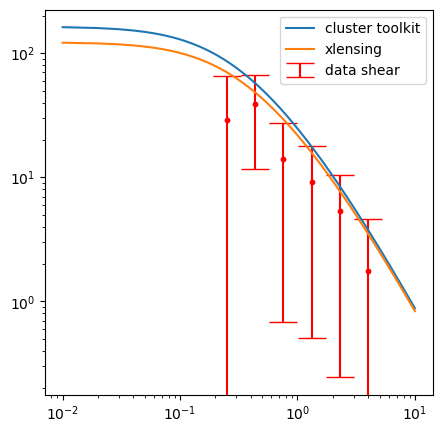

In [41]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data shear')
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Fitting a single cluster

In [42]:
from scipy.stats import norm,multivariate_normal
from nautilus import Prior


In [43]:
prior = Prior()
prior.add_parameter('logMhalo', dist=(12,16))
prior.add_parameter('conc', dist=(1,10))

def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov)
    

In [44]:
param_test = {
    'logMhalo': 14,
    'conc': 5,
    
}
model_wrapper(param_test)

array([69.97083208, 48.24968344, 29.29697751, 15.82455765,  7.75293087,
        3.51879972])

In [45]:
loglike(param_test)

np.float64(-21.759082475271974)

In [46]:
from nautilus import Sampler

sampler = Sampler(prior, loglike, n_live=1000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 9      | 1        | 4        | 14200    | N/A    | 10042 | -21.75   


np.True_

In [47]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.6173 - 0.5562 + 0.1702
conc: 4.2474 - 1.5987 + 3.6116


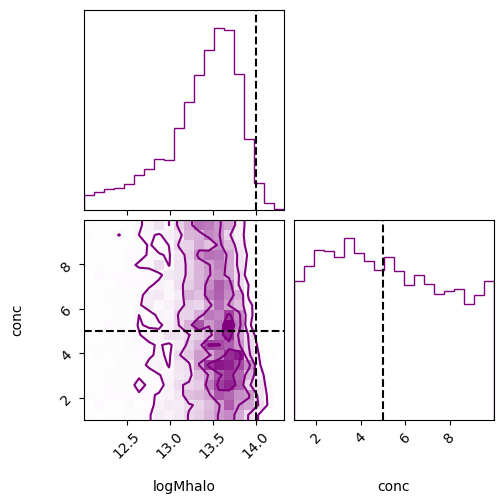

In [48]:
import corner
import matplotlib.pyplot as plt


figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [49]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████| 300/300 [00:19<00:00, 15.44it/s]


In [50]:
xlensing_true=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_true = xlensing_true['NFW Signal']

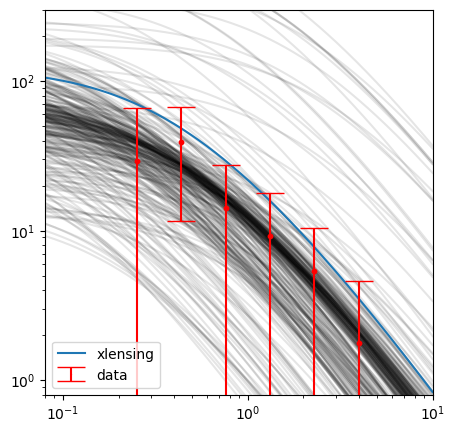

In [51]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Is it biased?

In [52]:
clusters = []
for i in tqdm.tqdm(range(100)):
    cluster_test = simcluster(gal_density=30,total_radius=10,z_range=[.3,2.],cluster=cluster,shape_noise=0.25,seed=None)
    clusters +=[cluster_test]
    

100%|█████████████████████████████████████████████████████████████████████████| 100/100 [46:33<00:00, 27.94s/it]


In [53]:
np.save("clusters.npy",clusters)

In [54]:
clusters = np.load("clusters.npy")

In [55]:
galaxy_catalogs = []

for cluster_test in clusters:
    galaxy_catalog = {}
    galaxy_catalog['RA'] = cluster_test['ra']
    galaxy_catalog['DEC'] = cluster_test['dec']
    galaxy_catalog['ZPHOT'] = cluster_test['z']
    galaxy_catalog['E1'] = cluster_test['e1']
    galaxy_catalog['E2'] = cluster_test['e2']
    galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
    galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
    galaxy_catalog = table.Table(galaxy_catalog)
    galaxy_catalogs += [galaxy_catalog]

In [56]:
sources_list = []
for galaxy_catalog in galaxy_catalogs:
    sr_RA = np.array(galaxy_catalog['RA'])
    sr_DEC= np.array(galaxy_catalog['DEC'])
    sr_z  = np.array(galaxy_catalog['ZPHOT'])
    sr_E1 = np.array(galaxy_catalog['E1'])
    sr_E2 = np.array(galaxy_catalog['E2'])
    sr_W = np.array(galaxy_catalog['WEIGHT'])
    sr_M = np.array(galaxy_catalog['M'])
    survey_lensing = partial(
        xlensing.data.lensfit_cluster_lensing,
        sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
        radius=10.
    )
    sources_list+=[(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M)]

In [59]:
survey_lensing = lambda sources : xlensing.data.lensfit_cluster_lensing(cluster=(cl_RA,cl_DEC,cl_z),sources=sources,radius=10.)

In [60]:
pool = Pool(cpu_count()) 
results=pool.map(survey_lensing,sources_list)
pool.close()
np.save("clusterbkgs.npy",results)

In [65]:
clusterbkgs = []
for result in results:
    Sigma_crit = np.array(result['Critical Density'])
    e_t = np.array(result['Tangential Shear'])
    e_x = np.array(result['Critical Density'])
    W = np.array(result['Weights'])
    M = np.array(result['Mult. Bias'])
    R = np.array(result['Radial Distance'])
    clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))

In [66]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[14, 59, 180, 591, 1700, 5176]

Single cluster:
Separating galaxies per radial bin...


In [67]:
sigmas_stack, boosts_stack, sigmas_cov_stack, xigmas_stack, xigmas_cov_stack = xlensing.data.stacked_signal(clusterbkgs,bins_lims,Nboot)

Total galaxies available per bin:
[  2027   6322  18975  57779 174300 526733]



100%|███████████████████████████████████████████████████████████████████████| 1000/1000 [02:20<00:00,  7.11it/s]


In [68]:
singles = []
for bkg in tqdm.tqdm(clusterbkgs):
    sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single = xlensing.data.single_cluster([bkg],bins_lims,Nboot)
    singles +=[(sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single)]

  0%|                                                                                   | 0/100 [00:00<?, ?it/s]

Total galaxies available per bin:
[14, 59, 180, 591, 1700, 5176]

Single cluster:
Separating galaxies per radial bin...


  1%|▊                                                                          | 1/100 [00:02<03:25,  2.08s/it]

Total galaxies available per bin:
[24, 78, 194, 547, 1762, 5315]

Single cluster:
Separating galaxies per radial bin...


  2%|█▌                                                                         | 2/100 [00:04<03:25,  2.10s/it]

...

 98%|████████████████████████████████████████████████████████████████████████▌ | 98/100 [03:20<00:04,  2.36s/it]

Total galaxies available per bin:
[19, 56, 211, 581, 1686, 5298]

Single cluster:
Separating galaxies per radial bin...


 99%|█████████████████████████████████████████████████████████████████████████▎| 99/100 [03:22<00:02,  2.40s/it]

Total galaxies available per bin:
[25, 59, 199, 592, 1812, 5316]

Single cluster:
Separating galaxies per radial bin...


100%|█████████████████████████████████████████████████████████████████████████| 100/100 [03:22<00:00,  2.03s/it]


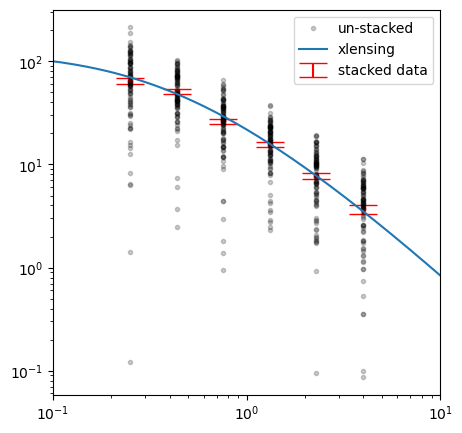

In [82]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='stacked data')

for index, single in enumerate(singles):
    if index==0:
        plt.plot(radii,single[0],'k.',alpha=.2,label='un-stacked')
    else:
        plt.plot(radii,single[0],'k.',alpha=.2)
plt.xlim([.1,1e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)

plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()

In [70]:
def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas_stack
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov_stack)
    

In [71]:
sampler = Sampler(prior, loglike, n_live=4000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 70770    | N/A    | 22077 | -16.07   


np.True_

In [72]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.9955 - 0.1276 + 0.0315
conc: 4.7805 - 0.6049 + 1.5992


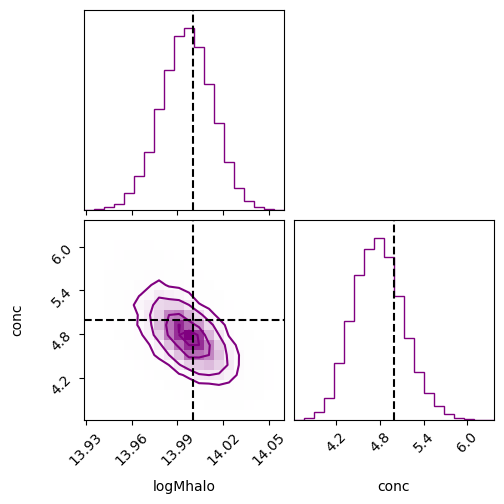

In [73]:
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [74]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████| 300/300 [00:25<00:00, 11.87it/s]


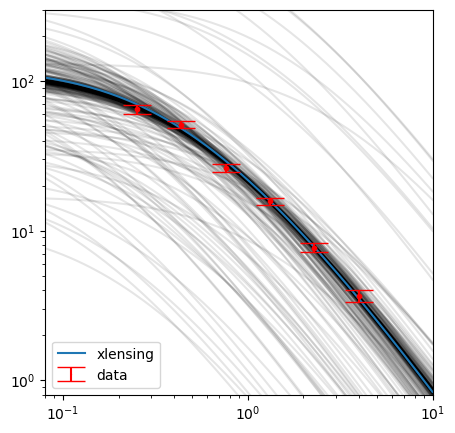

In [75]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()

In [76]:
single_fits = []
for single in tqdm.tqdm(singles):
    sigmas_single = single[0]
    sigmas_cov_single = single[1]
    def loglike(param_dict):
        model=model_wrapper(param_dict)
        data=sigmas_single
        return multivariate_normal.logpdf(model-data,cov=sigmas_cov_single)
    sampler = Sampler(prior, loglike, n_live=1000,pool=15)
    sampler.run(verbose=False)
    points, log_w, log_l = sampler.posterior()
    single_fits +=[(points, log_w, log_l)]
    del sampler
        

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 11     | 1        | 4        | 15645    | N/A    | 10005 | -24.38   
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 11     | 1        | 4        | 15855    | N/A    | 10098 | -24.62   
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 10     | 1        | 4        | 14910    | N/A    | 10028 | -24.51   
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 9      | 1        | 4        | 14070    | N/A    | 10037 | -2

In [ ]:
single_fit[1]

In [78]:
allchains=np.vstack([single_fit[0] for single_fit in single_fits])

In [79]:
allweights=np.hstack([single_fit[1] for single_fit in single_fits])

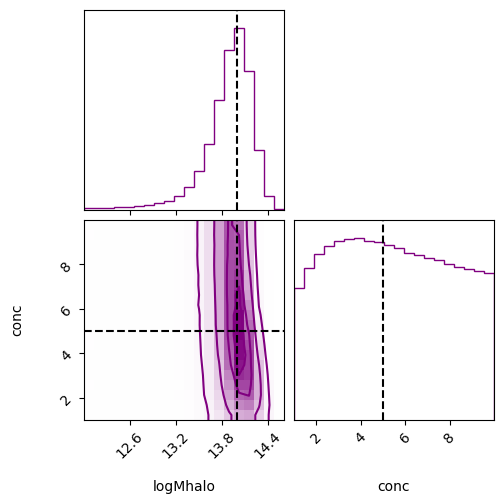

In [80]:
figure = corner.corner(
    allchains, weights=np.exp(allweights), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))
corner.overplot_lines(figure, [14,5], color="black", linestyle="--")